# Product metadata & feature review

Exploratory, as of 30 April 2011, on 200 selected SKUs. These are candidate features, not verified categories, quality or product origin. No model is trained in this notebook. Run `scripts/build_product_features.py` and `scripts/review_product_features.py` first.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
folder = ROOT / 'reports/generated'
data = pd.read_csv(folder / 'product-features.csv', dtype={'stock_code': str, 'candidate_code_base': str})
sample = pd.read_csv(folder / 'product-feature-sample.csv', dtype={'stock_code': str, 'candidate_code_base': str})
profile = json.loads((folder / 'product-feature-profile.json').read_text())
print(f'{len(data)} products, {len(data.columns)} columns; cutoff: {data.as_of.iloc[0]}')

200 products, 27 columns; cutoff: 2011-04-30


## Random sample for review
A fixed seed of 42 selected 20 products. Compare the original description with the literal tags, candidate pack size and code format. Missing pack size means no recognized pattern, not that a product is sold individually.

In [2]:
display(sample.fillna("—"))

/home/bmage/projects/retailmind-ai-forecasting/.cache/tmp/ipykernel_9972/782230728.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(sample.fillna("—"))


,stock_code,description,code_shape,candidate_code_base,candidate_pack_size,weighted_mean_price_lookback,uk_units_share_lookback,literal_tags
0,22382,LUNCH BAG SPACEBOY DESIGN,numeric,—,—,1.742314,0.669149,bag
1,17003,BROCADE RING PURSE,numeric,—,—,0.260723,0.983418,—
2,20726,LUNCH BAG WOODLAND,numeric,—,—,1.724566,0.697073,bag
3,51020B,STRIPY DESIGN SHOWER CAP,numeric_with_suffix,51020,—,0.290000,1.000000,—
4,22707,WRAP MONSTER FUN,numeric,—,—,0.420000,1.000000,—
5,22547,MINI JIGSAW DINOSAUR,numeric,—,—,0.449126,0.606557,—
6,21981,PACK OF 12 WOODLAND TISSUES,numeric,—,12.0,0.254201,0.684211,pack
7,82001S,VINYL RECORD FRAME SILVER,numeric_with_suffix,82001,—,3.487447,1.000000,—
8,84508A,CAMOUFLAGE DESIGN TEDDY,numeric_with_suffix,84508,—,2.108282,1.000000,—
9,21207,SKULL AND CROSSBONES GARLAND,numeric,—,—,1.539195,0.586207,—


## Unique values, missingness and coverage
Identifiers and descriptions may have many distinct values; numeric features use quantiles rather than an unreadable list. Binary-tag counts show the exact observed values in this 200-product sample.

In [3]:
summary = pd.DataFrame([{'feature': k, 'non_null_unique': v['unique_non_null'], 'missing': v['missing'], 'values_or_quantiles': v.get('value_counts', v.get('quantiles', {}))} for k,v in profile.items()])
display(summary)

,feature,non_null_unique,missing,values_or_quantiles
0,stock_code,200,0,{}
1,as_of,1,0,{'2011-04-30': 200}
2,description,200,0,{}
3,code_shape,2,0,"{'numeric': 170, 'numeric_with_suffix': 30}"
4,candidate_code_base,23,170,{}
5,candidate_pack_size,6,182,"{'12.0': 7, '20.0': 2, '35.0': 1, '6.0': 3, '6..."
6,sales_units_lookback,182,0,"{'0.0': 158.0, '0.25': 294.0, '0.5': 1823.0, '..."
7,weighted_mean_price_lookback,193,0,"{'0.0': 0.06618952419032385, '0.25': 0.3938291..."
8,invoice_count_lookback,104,0,"{'0.0': 3.0, '0.25': 10.0, '0.5': 18.0, '0.75'..."
9,uk_units_share_lookback,138,0,"{'0.0': 0.03225806451612903, '0.25': 0.8179141..."


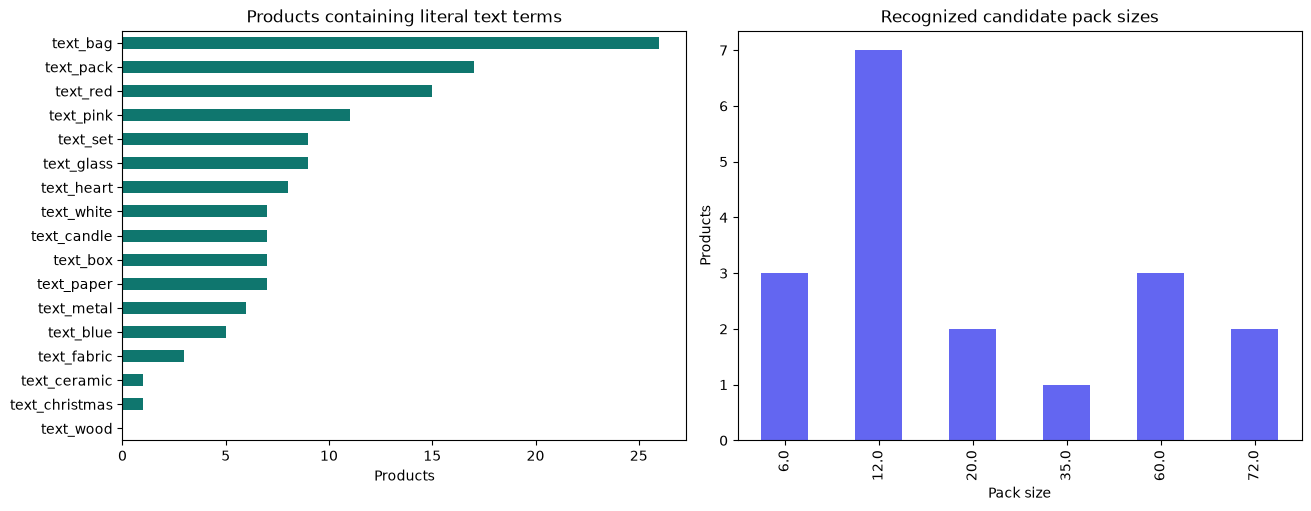

Pack size not recognized: 182 of 200


In [4]:
tags=[x for x in data.columns if x.startswith('text_')]
counts=data[tags].sum().sort_values(ascending=True)
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
counts.plot.barh(ax=axes[0],color='#0f766e');axes[0].set(title='Products containing literal text terms',xlabel='Products')
data.candidate_pack_size.value_counts().sort_index().plot.bar(ax=axes[1],color='#6366f1');axes[1].set(title='Recognized candidate pack sizes',xlabel='Pack size',ylabel='Products')
plt.show()
print('Pack size not recognized:', int(data.candidate_pack_size.isna().sum()), 'of',len(data))

## Code-family pattern
Some numeric bases with alphabetic suffixes occur on similarly described products, but this is not a documented coding rule. Display every repeated base in the sample for manual checking.

In [5]:
pairs=data[data.candidate_code_base.notna()].groupby('candidate_code_base').filter(lambda g: len(g)>1)
display(pairs[['stock_code','candidate_code_base','description']].sort_values(['candidate_code_base','stock_code']))

,stock_code,candidate_code_base,description
143,35095A,35095,BLUE VICTORIAN FABRIC OVAL BOX
144,35095B,35095,RED VICTORIAN FABRIC OVAL BOX
157,51020A,51020,SUMMER FUN DESIGN SHOWER CAP
158,51020B,51020,STRIPY DESIGN SHOWER CAP
188,85099B,85099,JUMBO BAG RED RETROSPOT
189,85099C,85099,JUMBO BAG BAROQUE BLACK WHITE
190,85099F,85099,JUMBO BAG STRAWBERRY
196,85230A,85230,OPIUM SCENTED VOTIVE CANDLE
197,85230B,85230,CINNAMON SCENTED VOTIVE CANDLE
198,85230E,85230,STRAWBRY SCENTED VOTIVE CANDLE


## Review observations and limitations
- `PACK OF 12 WOODLAND TISSUES` yields 12 and `PACK OF 60 DINOSAUR CAKE CASES` yields 60. `60 TEATIME FAIRY CAKE CASES` is a plausible missed pack-size pattern and remains unclassified by design.
- `BAG 125G SWIRLY MARBLES` shows that the word BAG may describe packaging rather than product category. A literal tag must not be represented as a verified product type.
- Similar descriptions for 35095A/B and 85230A/B/E/G suggest potential variants; check more examples before applying a family rule.
- Prices and customer-country shares are historical, not future values; missing values are distinct from zero. Neither product quality nor production origin is established.
- The sample is selected, not representative of all 4,894 products. Any text vocabulary or category classifier must be fitted using only data available to the training fold.